[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D6_svm_margen.ipynb)

# D6 · SVM: margen $2/\lVert\vec w\rVert$, margen suave y los dos tipos de vectores de soporte

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód I + Mód III).** Distancia de un punto a un hiperplano: $|\vec w\cdot x_0+b|/\lVert\vec w\rVert$. KKT: holgura complementaria.

**Supuestos.** $y\in\{-1,+1\}$. Margen duro requiere separabilidad; margen suave no. `SVC` con hinge y sin regularizar $b$; $C$ = peso del error. Las variables están en escalas comparables.

**La idea.** $2/\lVert\vec w\rVert$ es la distancia entre los planos canónicos $\vec w\cdot x+b=\pm 1$. En margen suave: si $0<\alpha_i<C$, el punto está **sobre** un plano; si $\alpha_i=C$, puede estar dentro del margen o mal clasificado.

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
LOG10_C = 0.0   # C = 10**LOG10_C

## La identidad, con números

C = 1   ‖w‖ = 1.6999   2/‖w‖ = 1.1766   distancia medida = 1.1766
vectores de soporte: 10  (0<α<C: 3, α=C: 7)
  y·f de los α<C (deberían ser 1): [1. 1. 1.]
  α=C mal clasificados: 2, dentro del margen: 5


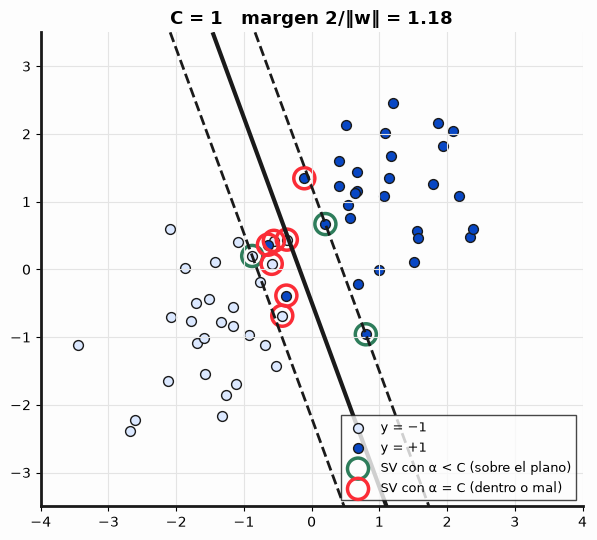

In [3]:
from sklearn.svm import SVC

rng = np.random.default_rng(6)
Xn = rng.normal(loc=[-1.4, -1.0], scale=0.8, size=(30, 2))
Xp = rng.normal(loc=[1.4, 1.0], scale=0.8, size=(30, 2))
X = np.vstack([Xn, Xp]); y = np.r_[-np.ones(30), np.ones(30)]

def demo(log10_c=LOG10_C):
    Cv = 10 ** log10_c
    svm = SVC(kernel="linear", C=Cv, tol=1e-8).fit(X, y)
    w, b = svm.coef_[0], svm.intercept_[0]
    alpha = np.abs(svm.dual_coef_[0])                 # dual_coef_ = α_i y_i
    sv = svm.support_
    f = X @ w + b
    # distancia medida entre los planos: proyectamos un punto de cada plano sobre la normal
    x_mas = -(b - 1) * w / (w @ w); x_menos = -(b + 1) * w / (w @ w)
    dist = np.linalg.norm(x_mas - x_menos)
    print(f"C = {Cv:.3g}   ‖w‖ = {np.linalg.norm(w):.4f}   2/‖w‖ = {2/np.linalg.norm(w):.4f}   distancia medida = {dist:.4f}")
    assert np.isclose(dist, 2 / np.linalg.norm(w))
    en_plano = alpha < Cv * (1 - 1e-6)
    print(f"vectores de soporte: {len(sv)}  (0<α<C: {en_plano.sum()}, α=C: {(~en_plano).sum()})")
    yf = y[sv] * f[sv]
    print("  y·f de los α<C (deberían ser 1):", np.round(yf[en_plano], 4))
    if en_plano.any():
        assert np.allclose(yf[en_plano], 1, atol=1e-3)
    assert (yf[~en_plano] <= 1 + 1e-3).all()
    print(f"  α=C mal clasificados: {(yf[~en_plano] < 0).sum()}, dentro del margen: {((yf[~en_plano] >= 0) & (yf[~en_plano] < 1 - 1e-3)).sum()}")

    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    xx, yy = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-3.5, 3.5, 300))
    F = w[0] * xx + w[1] * yy + b
    ax.contour(xx, yy, F, levels=[-1, 0, 1], colors=[C["tinta"]] * 3, linestyles=["--", "-", "--"], linewidths=[2, 3, 2])
    ax.scatter(*Xn.T, color=C["datos"], edgecolor=C["tinta"], s=50, label="y = −1")
    ax.scatter(*Xp.T, color=C["w"], edgecolor=C["tinta"], s=50, label="y = +1")
    ax.scatter(*X[sv[en_plano]].T, s=230, facecolor="none", edgecolor=C["yhat"], linewidth=2.5, label="SV con α < C (sobre el plano)")
    ax.scatter(*X[sv[~en_plano]].T, s=230, facecolor="none", edgecolor=C["error"], linewidth=2.5, label="SV con α = C (dentro o mal)")
    ax.set(xlim=(-4, 4), ylim=(-3.5, 3.5), aspect="equal", title=f"C = {Cv:.3g}   margen 2/‖w‖ = {2/np.linalg.norm(w):.2f}")
    ax.legend(loc="lower right", fontsize=9)
    fig.tight_layout(); plt.show()

demo()

**¿Qué pasa si…?** Predigan: al subir $C$, ¿el margen se ensancha o se angosta? ¿Hay más o menos vectores de soporte?

Respuesta esperada: se angosta y hay menos vectores de soporte (los errores se vuelven caros). Con $C$ chico el margen es ancho y casi todos los puntos cercanos son vectores de soporte con $\alpha_i=C$.

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, log10_c=W.FloatSlider(value=LOG10_C, min=-2.5, max=3, step=0.25, description='log₁₀ C', continuous_update=False))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')